### Project 2

1.   Identify a large 2-node network dataset—you can start with a dataset in a repository.  Your data should meet the criteria that it consists of ties between and not within two (or more) distinct groups.
2.   Reduce the size of the network using a method such as the island method described in chapter 4 of social network analysis.
3.   What can you infer about each of the distinct groups?

You may work in a small group on the project. Your code and analysis should be delivered in an IPython Notebook by end of day Monday


#### Introduction

The goal of this project is to analyze relationships between music listeners and artists using two-mode network analysis. The project uses the HetRec 2011 Last.fm dataset, which contains 92,834 user–artist relationships. Each row represents a connection between a user and an artist, and the weight column records the number of times the user listened to that artist.

The dataset contains two distinct groups: users and artists, with connections occurring only between the groups. By representing users and artists as nodes and listening relationships as weighted edges, this project examines patterns in listening activity and the structure of the relationships between the two groups.

Beyond reducing the network's size, the main objective is to determine what can be inferred about each group. For users, the analysis examines differences in the breadth and intensity of their listening relationships. For artists, it examines differences in audience reach and cumulative listening activity. The island method is then used to focus on stronger listening relationships and investigate how these relationships shape the structure of the network.

#### Install and import the tools

I import the Python libraries needed to download, process, analyze, and visualize the Last.fm dataset. Pandas and NumPy support data manipulation, Matplotlib and Seaborn create visualizations, Requests downloads the dataset, and itertools helps work with combinations.

In [1]:
import networkx as nx
import requests
import itertools
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
from io import BytesIO

### Download and load the dataset

I downloaded the HetRec 2011 Last.fm dataset from the GroupLens repository and loaded the user–artist relationships into a dataframe containing 92,834 rows and three columns: userID, artistID, and weight. Each row represents a connection between a user and an artist, while the weight records the number of times the user listened to that artist. For example, user 2 listened to artist 51 a total of 13,883 times.

This dataset is suitable for two-mode network analysis because it contains two distinct groups: users and artists. The listening relationships form weighted edges between these groups, providing the basis for reducing the network using the island method and investigating patterns in user behavior and artist popularity.

In [2]:
url = (
    "https://files.grouplens.org/datasets/"
    "hetrec2011/hetrec2011-lastfm-2k.zip")

response = requests.get(url, timeout=120)
response.raise_for_status()

with zipfile.ZipFile(BytesIO(response.content)) as z:
    print(z.namelist())

    with z.open("user_artists.dat") as f:
        edges_df = pd.read_csv(f, sep="\t")

print("Shape:", edges_df.shape)
display(edges_df.head())

['user_friends.dat', 'user_taggedartists.dat', 'user_taggedartists-timestamps.dat', 'artists.dat', 'readme.txt', 'tags.dat', 'user_artists.dat']
Shape: (92834, 3)


,userID,artistID,weight
0,2,51,13883
1,2,52,11690
2,2,53,11351
3,2,54,10300
4,2,55,8983


#### Load and Merge Artist Information

I loaded the artist metadata from the HetRec 2011 Last.fm dataset and merged it with the listening data to replace numerical artist IDs with recognizable names. The metadata contains 17,632 artist records, including IDs, names, and links to artist pages and pictures. I used validate="many_to_one" to ensure that each artist ID matched no more than one metadata record.

After merging, the dataset contained 92,834 rows and four columns: userID, artistID, weight, and artist_name. The number of rows remained unchanged, and there were no missing artist names, confirming that all listening relationships were preserved and all 17,632 artists had matching metadata. Adding artist names makes the network results easier to interpret, particularly when identifying artists with the most user connections and the highest listening strength.

In [3]:
# Load the artist metadata
with zipfile.ZipFile(BytesIO(response.content)) as z:
    artists_df = pd.read_csv(
        z.open("artists.dat"),
        sep="\t")

print("Artists table shape:", artists_df.shape)
print("Columns:", artists_df.columns.tolist())

display(artists_df.head(10))

# Rename metadata columns
artists_df = artists_df.rename(columns={
    "id": "artistID",
    "name": "artist_name"})

# Merge artist names into the user–artist relationships
edges_named = edges_df.merge(
    artists_df[["artistID", "artist_name"]],
    on="artistID",
    how="left",
    validate="many_to_one")

# Inspect the merged dataset
print("Merged dataset shape:", edges_named.shape)
display(edges_named.head(10))

# Count artist relationships without a matching name
missing_artist_names = edges_named["artist_name"].isna().sum()

print("Relationships without artist names:", missing_artist_names)
print(
    "Unique artists in listening data:",
    edges_df["artistID"].nunique())
print(
    "Unique artists with matched names:",
    edges_named.loc[
        edges_named["artist_name"].notna(), "artistID"
    ].nunique())

Artists table shape: (17632, 4)
Columns: ['id', 'name', 'url', 'pictureURL']


,id,name,url,pictureURL
0,1,MALICE MIZER,http://www.last.fm/music/MALICE+MIZER,http://userserve-ak.last.fm/serve/252/10808.jpg
1,2,Diary of Dreams,http://www.last.fm/music/Diary+of+Dreams,http://userserve-ak.last.fm/serve/252/3052066.jpg
2,3,Carpathian Forest,http://www.last.fm/music/Carpathian+Forest,http://userserve-ak.last.fm/serve/252/40222717...
3,4,Moi dix Mois,http://www.last.fm/music/Moi+dix+Mois,http://userserve-ak.last.fm/serve/252/54697835...
4,5,Bella Morte,http://www.last.fm/music/Bella+Morte,http://userserve-ak.last.fm/serve/252/14789013...
5,6,Moonspell,http://www.last.fm/music/Moonspell,http://userserve-ak.last.fm/serve/252/2181591.jpg
6,7,Marilyn Manson,http://www.last.fm/music/Marilyn+Manson,http://userserve-ak.last.fm/serve/252/2558217.jpg
7,8,DIR EN GREY,http://www.last.fm/music/DIR+EN+GREY,http://userserve-ak.last.fm/serve/252/46968835...
8,9,Combichrist,http://www.last.fm/music/Combichrist,http://userserve-ak.last.fm/serve/252/51273485...
9,10,Grendel,http://www.last.fm/music/Grendel,http://userserve-ak.last.fm/serve/252/5872875.jpg


Merged dataset shape: (92834, 4)


,userID,artistID,weight,artist_name
0,2,51,13883,Duran Duran
1,2,52,11690,Morcheeba
2,2,53,11351,Air
3,2,54,10300,Hooverphonic
4,2,55,8983,Kylie Minogue
5,2,56,6152,Daft Punk
6,2,57,5955,Thievery Corporation
7,2,58,4616,Goldfrapp
8,2,59,4337,New Order
9,2,60,4147,Matt Bianco


Relationships without artist names: 0
Unique artists in listening data: 17632
Unique artists with matched names: 17632


#### Inspecting and Validating the Dataset

I inspected the merged dataset to verify its completeness and consistency before constructing the two-mode network. The dataset contains 92,834 user–artist relationships and four columns: userID, artistID, weight, and artist_name. The data types are appropriate for representing user and artist identifiers, listening counts, and artist names.

The validation checks found no missing values, duplicate rows, or duplicate user–artist pairs. The dataset contains 1,892 unique users and 17,632 unique artists, establishing the sizes of the two distinct groups.

These results confirm that the dataset is structurally suitable for constructing a bipartite network, with each recorded relationship represented by a separate weighted edge between a user and an artist.

In [4]:
# Inspect the dataset and data types

display(edges_named.head())
# Shape
print("Dataset shape:", edges_named.shape)
# column names, data types, and non-null counts
edges_named.info()
# Summary statistics for numerical columns
display(edges_named[["userID", "artistID", "weight"]].describe())

# Missingness
print("Missing values per column:")
print(edges_named.isnull().sum())
print("\nTotal missing values:", edges_named.isnull().sum().sum())

# Duplicate rows and user–artist pairs
# Check for completely duplicated rows
print("Duplicate rows:", edges_named.duplicated().sum())

# Repeated user–artist relationships
duplicate_pairs = edges_named.duplicated(
    subset=["userID", "artistID"]
).sum()

print("Duplicate user–artist pairs:", duplicate_pairs)

#Count unique users and artists
num_users = edges_named["userID"].nunique()
num_artists = edges_named["artistID"].nunique()
num_relationships = len(edges_named)

print("Unique users:", num_users)
print("Unique artists:", num_artists)
print("Total listening relationships:", num_relationships)

,userID,artistID,weight,artist_name
0,2,51,13883,Duran Duran
1,2,52,11690,Morcheeba
2,2,53,11351,Air
3,2,54,10300,Hooverphonic
4,2,55,8983,Kylie Minogue


Dataset shape: (92834, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92834 entries, 0 to 92833
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   userID       92834 non-null  int64 
 1   artistID     92834 non-null  int64 
 2   weight       92834 non-null  int64 
 3   artist_name  92834 non-null  object
dtypes: int64(3), object(1)
memory usage: 2.8+ MB


,userID,artistID,weight
count,92834.000000,92834.000000,92834.00000
mean,1037.010481,3331.123145,745.24393
std,610.870436,4383.590502,3751.32208
min,2.000000,1.000000,1.00000
25%,502.000000,436.000000,107.00000
50%,1029.000000,1246.000000,260.00000
75%,1568.000000,4350.000000,614.00000
max,2100.000000,18745.000000,352698.00000


Missing values per column:
userID         0
artistID       0
weight         0
artist_name    0
dtype: int64

Total missing values: 0
Duplicate rows: 0
Duplicate user–artist pairs: 0
Unique users: 1892
Unique artists: 17632
Total listening relationships: 92834


#### Analyzing the Distribution of Listening Weights

I analyzed the distribution of listening weights using summary statistics and histograms to understand the strength of user–artist relationships. The weight represents the number of times a user listened to an artist and determines the strength of the corresponding edge in the network. Examining this distribution is important because the island method will use listening-weight thresholds to reduce the network and retain stronger relationships.

The dataset contains 92,834 user–artist relationships, with weights ranging from 1 to 352,698. The mean is approximately 745.24, while the median is 260, and the standard deviation is approximately 3,751.32. The 25th, 75th, 90th, 95th, and 99th percentiles are 107, 614, 1,387, 2,328, and approximately 7,228, respectively. The difference between the mean and median indicates a highly uneven distribution, in which most relationships have relatively low listening counts and a small proportion have exceptionally high values.

The first histogram, Distribution of User–Artist Listening Weights, shows a strongly right-skewed distribution with a long tail extending toward higher listening counts. Because a small number of relationships have very high weights, most observations are concentrated near the lower end of the scale, making them difficult to distinguish in the original plot.

The second histogram uses a logarithmic scale on the horizontal axis, making it easier to compare listening weights across a wide range of values. The third histogram displays the base-10 logarithm of the weights and shows a peak around values of 2.5–2.7, corresponding to approximately 316–501 listens. Together, these visualizations provide a clearer understanding of the variation in listening intensity across user–artist relationships.

Additional validation checks confirmed that all 92,834 listening weights are positive integers, with no zero, negative, or non-integer values. The data therefore meets the basic consistency requirements for the subsequent analysis. The results show that listening activity is unevenly distributed across both groups' relationships: some user–artist connections have substantially higher weights than others. This supports using the island method to investigate how the network changes as weaker relationships are filtered out. I will compare several percentile-based thresholds to identify a balance between reducing network complexity and retaining a sufficiently connected structure for analyzing differences between users and artists.

Minimum weight: 1
Maximum weight: 352698
Mean weight: 745.2439300256372
Median weight: 260.0
Standard deviation: 3751.322080387676


,weight
0.00,1.00
0.25,107.00
0.50,260.00
0.75,614.00
0.90,1387.00
0.95,2328.00
0.99,7228.01
1.00,352698.00


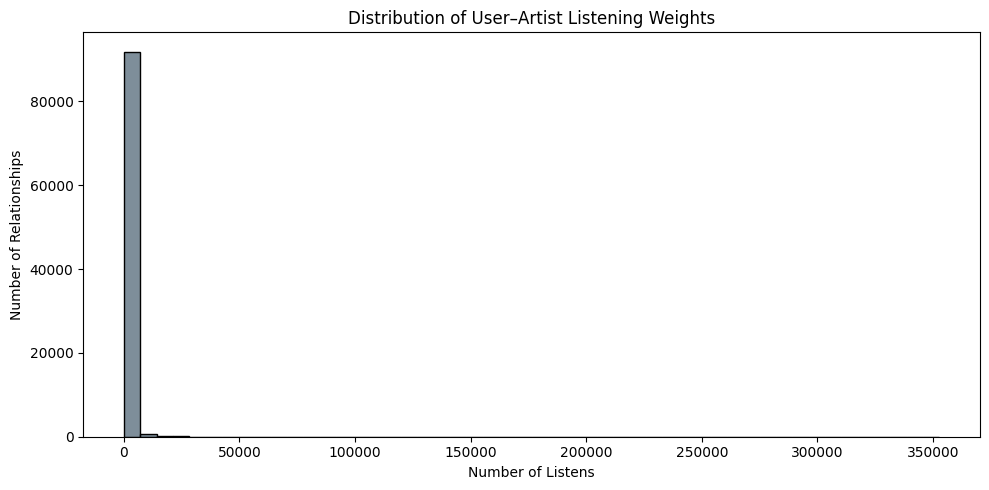

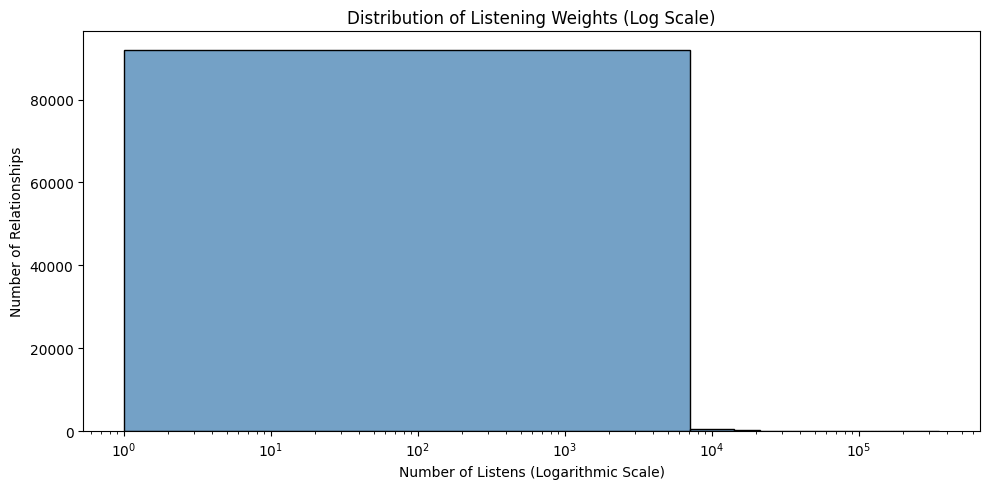

Zero or negative weights: 0
Non-integer weights: 0
count     92834.00000
mean        745.24393
std        3751.32208
min           1.00000
25%         107.00000
50%         260.00000
75%         614.00000
90%        1387.00000
95%        2328.00000
99%        7228.01000
max      352698.00000
Name: weight, dtype: float64


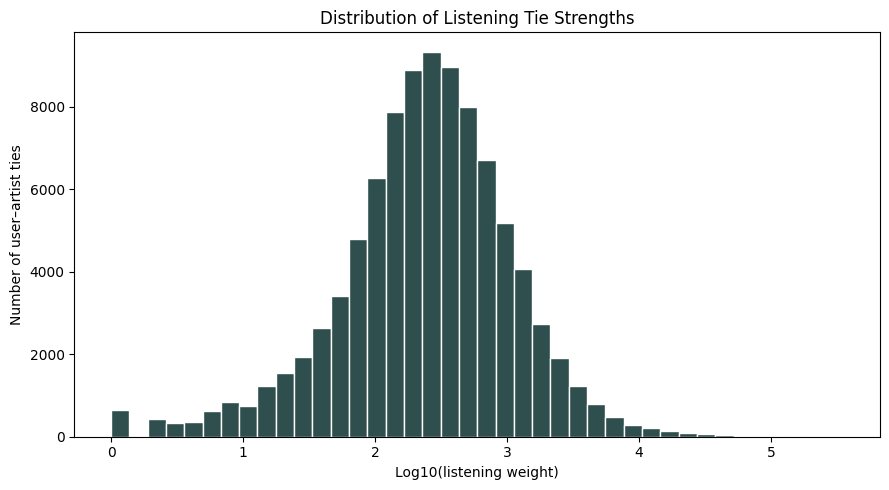

In [5]:
#Examine listening-weight distributions
# Summary statistics for listening counts
print("Minimum weight:", edges_named["weight"].min())
print("Maximum weight:", edges_named["weight"].max())
print("Mean weight:", edges_named["weight"].mean())
print("Median weight:", edges_named["weight"].median())
print("Standard deviation:", edges_named["weight"].std())

# Selected percentiles
display(
    edges_named["weight"].quantile(
        [0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1]
    )
)

# Visualize the distribution of listening weights
plt.figure(figsize=(10, 5))
sns.histplot(data=edges_named, x="weight", bins=50, color="#536878")

plt.title("Distribution of User–Artist Listening Weights")
plt.xlabel("Number of Listens")
plt.ylabel("Number of Relationships")

plt.tight_layout()
plt.show()

#Visualize the distribution using a logarithmic scale

plt.figure(figsize=(10, 5))

sns.histplot(data=edges_named, x="weight", bins=50, color="#4682B4")
plt.xscale("log")

plt.title("Distribution of Listening Weights (Log Scale)")
plt.xlabel("Number of Listens (Logarithmic Scale)")
plt.ylabel("Number of Relationships")

plt.tight_layout()
plt.show()

# Check whether listening weights are valid

print("Zero or negative weights:", (edges_named["weight"] <= 0).sum())
print("Non-integer weights:", (edges_named["weight"] % 1 != 0).sum())

print(edges_named["weight"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))

plt.figure(figsize=(9, 5))

plt.hist(
    np.log10(edges_named["weight"]),
    bins=40,
    color="#2F4F4F",
    edgecolor="white")

plt.xlabel("Log10(listening weight)")
plt.ylabel("Number of user–artist ties")
plt.title("Distribution of Listening Tie Strengths")
plt.tight_layout()
plt.show()

#### Exploring the Most-Listened-to Artists

I identified and visualized the 15 artists with the highest total listening counts to establish a baseline for understanding artist popularity before reducing the network. The bar chart shows that Britney Spears ranks first, with approximately 2.4 million recorded plays, followed by Depeche Mode and Lady Gaga, with approximately 1.3 million plays each. Other artists in the top 15 include Christina Aguilera, Paramore, Madonna, Rihanna, Beyoncé, Glee Cast, Evanescence, Taylor Swift, Avril Lavigne, and Katy Perry.

These results suggest that listening activity is unevenly distributed across artists, with some accumulating substantially more plays than others. However, total plays do not necessarily reflect audience size, since high totals may result from either a large audience or frequent listening by a smaller group. This highlights an important distinction within the artist group: audience reach and listening intensity are different measures of popularity. The subsequent analysis compares unique listeners and listening strength to investigate these differences and examine how artists are connected to users in the two-mode network.

,artistID,artist_name,total_plays,number_of_listeners
283,289,Britney Spears,2393140,522
66,72,Depeche Mode,1301308,282
83,89,Lady Gaga,1291387,611
286,292,Christina Aguilera,1058405,407
492,498,Paramore,963449,399
61,67,Madonna,921198,429
282,288,Rihanna,905423,484
695,701,Shakira,688529,319
221,227,The Beatles,662116,480
294,300,Katy Perry,532545,473


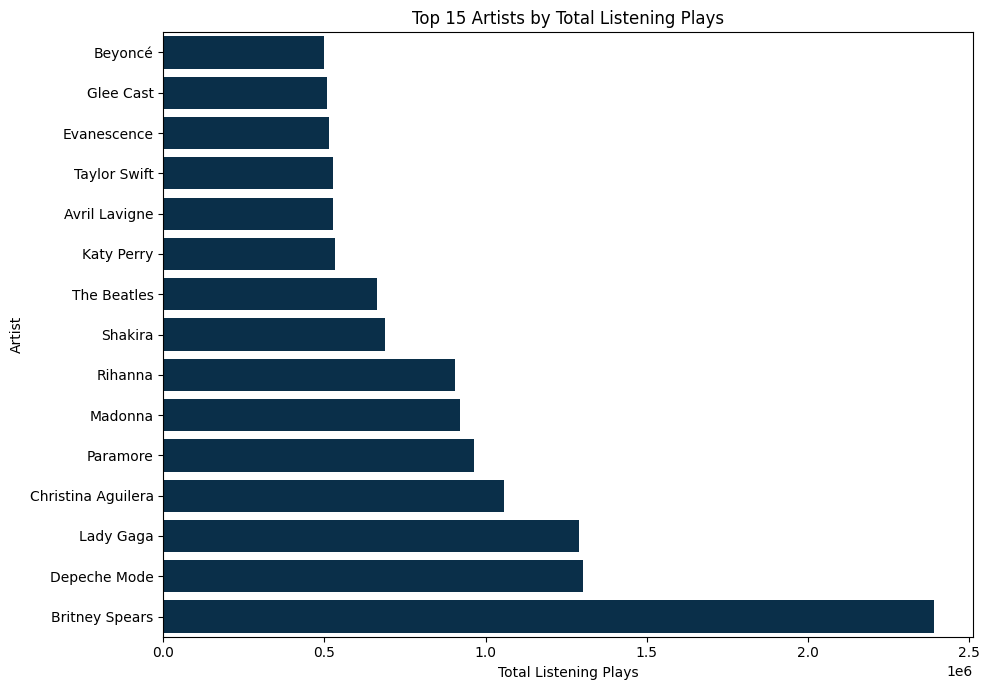

In [6]:
# Find the most-listened-to artists
top_artists = (
    edges_named.groupby(
        ["artistID", "artist_name"], as_index=False
    )
    .agg(
        total_plays=("weight", "sum"),
        number_of_listeners=("userID", "nunique")
    )
    .sort_values("total_plays", ascending=False)
)

display(top_artists.head(15))

# Prepare the top 15 artists for visualization
top15 = top_artists.head(15).sort_values("total_plays")

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top15,
    x="total_plays",
    y="artist_name",
    color="#003153"
)

plt.xlabel("Total Listening Plays")
plt.ylabel("Artist")
plt.title("Top 15 Artists by Total Listening Plays")
plt.tight_layout()
plt.show()

### Artist Audience Size vs. Listening Intensity

This code creates a scatter plot to explore the relationship between the number of unique listeners an artist has and their total listening plays in order to compare popularity with listening intensity. Each point represents an artist, allowing you to compare how many people listen to an artist with how often their music is played. The goal is to understand whether artists with larger audiences also tend to receive more total plays.

The horizontal axis represents the number of unique listeners, while the vertical axis represents total listening plays. Artists positioned further to the right have more listeners, while those higher up have more total plays. This comparison can help identify artists with large audiences and artists whose music may be played repeatedly by a smaller group of listeners.

The scatter plot shows a positive relationship between the number of unique listeners and total listening plays. In general, artists with larger audiences tend to accumulate more total plays. However, the relationship is not perfectly consistent, as artists with similar audience sizes can have noticeably different numbers of plays.

Most artists are clustered near the lower-left corner of the plot, indicating that they have relatively few unique listeners and lower total play counts. As the number of listeners increases, the spread of total plays becomes wider, suggesting that listening intensity varies considerably among artists.

There are also several outliers, including artists with approximately 300 listeners and 1.3 million plays, as well as an artist with around 520 listeners and 2.4 million plays. These artists have exceptionally high play counts compared with most others in the dataset. This may indicate frequent repeat listening, highly engaged audiences, or other factors that increase total plays.

The plot suggests that audience size contributes to total listening plays, but it does not fully explain listening intensity. Some artists may generate substantially more plays than expected for their audience size, potentially reflecting stronger listener engagement or repeated listening. To investigate this further, the ratio of total plays to unique listeners could be calculated for each artist. This would help identify artists whose audiences listen to their music most frequently, rather than simply identifying artists with the largest audiences.

In relation to the assignment's research question, the results suggest that artists differ in both audience reach and listening intensity. Artists with more unique listeners generally accumulate more plays, but some artists receive unusually high numbers of plays relative to their audience size. This indicates that audience size alone does not fully explain listening activity. From the user group's perspective, the results also highlight that listening activity can vary in intensity, although artist-level totals do not reveal the behavior of individual users. Overall, the comparison demonstrates why multiple measures are needed to understand the two groups.

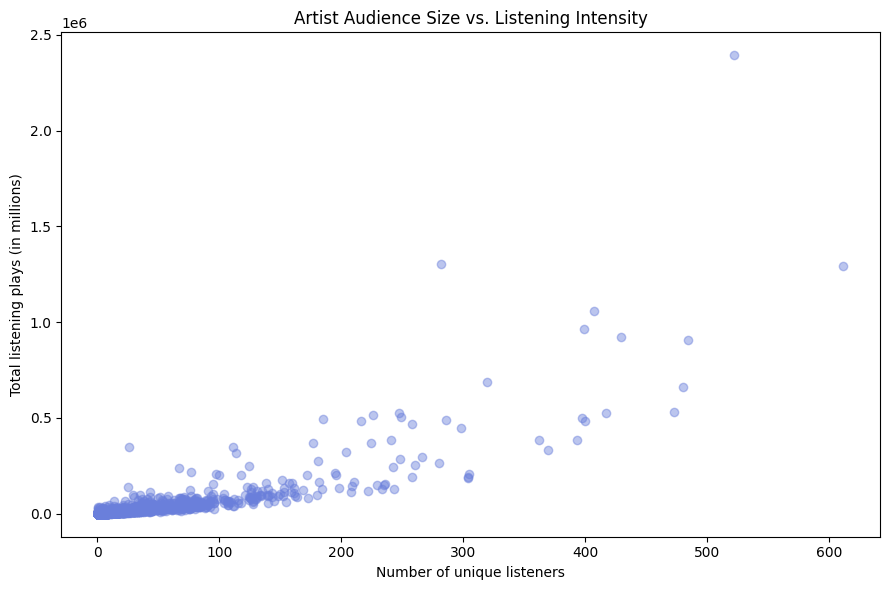

In [7]:
plt.figure(figsize=(9, 6))

plt.scatter(
    top_artists["number_of_listeners"],
    top_artists["total_plays"],
    alpha=0.45,
    color="#6A7FDB")

plt.xlabel("Number of unique listeners")
plt.ylabel("Total listening plays (in millions)")
plt.title("Artist Audience Size vs. Listening Intensity")
plt.tight_layout()
plt.show()


#### Constructing the Two-Mode Network

I constructed a two-mode, or bipartite network using NetworkX to represent the listening relationships between users and artists. Users and artists form two distinct groups of nodes, and edges connect only users to artists. Each edge is weighted by the number of times a user listened to a particular artist.

The resulting network contains 19,524 nodes and 92,834 edges, including 1,892 users and 17,632 artists. To verify the network's structure, I checked that every edge connects nodes from different groups. The check returned True, confirming that the graph satisfies the requirements of a bipartite network. I also verified an example relationship between user 2 and artist 51, whose edge weight is 13,883, matching the original dataset.

Constructing this network allows me to examine the structure of listening relationships while preserving the distinction between the two groups. It also provides the foundation for applying the island method to reduce the network and investigate what the remaining connections reveal about user listening behavior and artist popularity.

In [8]:
# Create an empty undirected graph
B = nx.Graph()

# Add user nodes
users = edges_named["userID"].unique()

B.add_nodes_from(
    [f"user_{user}" for user in users],
    bipartite=0,
    node_type="user"
)

# Add artist nodes
artists = edges_named["artistID"].unique()

artist_names = (
    edges_named[["artistID", "artist_name"]]
    .drop_duplicates(subset="artistID")
    .set_index("artistID")["artist_name"]
    .to_dict()
)

B.add_nodes_from(
    [
        (f"artist_{artist}", {
            "bipartite": 1,
            "node_type": "artist",
            "artist_name": artist_names[artist]
        })
        for artist in artists
    ]
)

# Add user–artist edges with listening weights
B.add_weighted_edges_from(
    [
        (f"user_{row.userID}",
         f"artist_{row.artistID}",
         row.weight)
        for row in edges_named.itertuples(index=False)
    ],
    weight="weight"
)

print("Number of nodes:", B.number_of_nodes())
print("Number of edges:", B.number_of_edges())

# verify
# Count nodes belonging to each group
user_nodes = [
    n for n, data in B.nodes(data=True)
    if data["node_type"] == "user"
]

artist_nodes = [
    n for n, data in B.nodes(data=True)
    if data["node_type"] == "artist"
]

print("User nodes:", len(user_nodes))
print("Artist nodes:", len(artist_nodes))
print("Total nodes:", B.number_of_nodes())
print("Total edges:", B.number_of_edges())

# Verify that every edge connects a user to an artist
valid_edges = all(
    B.nodes[u]["node_type"] != B.nodes[v]["node_type"]
    for u, v in B.edges()
)

print("All edges connect users to artists:", valid_edges)

# Inspect an example edge and its attributes
u, v = next(iter(B.edges()))

print("Example edge:", u, "<->", v)
print("Edge attributes:", B[u][v])

Number of nodes: 19524
Number of edges: 92834
User nodes: 1892
Artist nodes: 17632
Total nodes: 19524
Total edges: 92834
All edges connect users to artists: True
Example edge: user_2 <-> artist_51
Edge attributes: {'weight': 13883}


#### Projecting the Two-Mode Network onto Artists

I projected the bipartite network onto the artist group to examine audience overlap. In this projection, two artists are connected if at least one user listened to both, and edge weights represent the number of shared listeners. The resulting network contains 17,632 artists and 1,320,075 edges.

The Beatles have the highest degree, with connections to 5,925 other artists, followed by Lady Gaga with 5,285 and Radiohead with 5,242. However, Lady Gaga has the highest shared-listener strength at 29,668, followed by Britney Spears at 25,360 and The Beatles at 23,460. This shows that having connections to more artists does not necessarily mean having the highest cumulative number of shared listeners. Degree measures the number of connected artists, while weighted strength sums the shared listeners across those connections.

Because the projected network was very dense, I applied an additional threshold, retaining only artist pairs with at least 50 shared listeners and removing isolated nodes. The filtered network contains 194 artists and 1,623 edges, retaining approximately 1.1% of the original nodes and 0.1% of the edges.

This reduction makes it easier to examine artists with stronger audience overlap. However, the threshold of 50 is an analytical choice, and excluded connections may still represent meaningful relationships. Shared listeners also do not necessarily indicate similar musical styles or preferences, and shared-listener strength does not count unique individuals. Therefore, these results describe audience overlap within the Last.fm dataset rather than definitive measures of overall popularity.

Original bipartite network
Total nodes: 19524
Total edges: 92834

Artist projection
Artist nodes: 17632
Artist-to-artist edges: 1320075


,artistID,artist,connected_artists
176,227,The Beatles,5925
38,89,Lady Gaga,5285
103,154,Radiohead,5242
139,190,Muse,4848
14,65,Coldplay,4598
21,72,Depeche Mode,4346
238,289,Britney Spears,4236
16,67,Madonna,4108
112,163,Pink Floyd,3913
448,498,Paramore,3897


,artistID,artist,shared_listener_strength
38,89,Lady Gaga,29668
238,289,Britney Spears,25360
176,227,The Beatles,23460
237,288,Rihanna,23430
249,300,Katy Perry,23007
16,67,Madonna,20865
282,333,Avril Lavigne,20318
241,292,Christina Aguilera,19774
139,190,Muse,19550
448,498,Paramore,19493


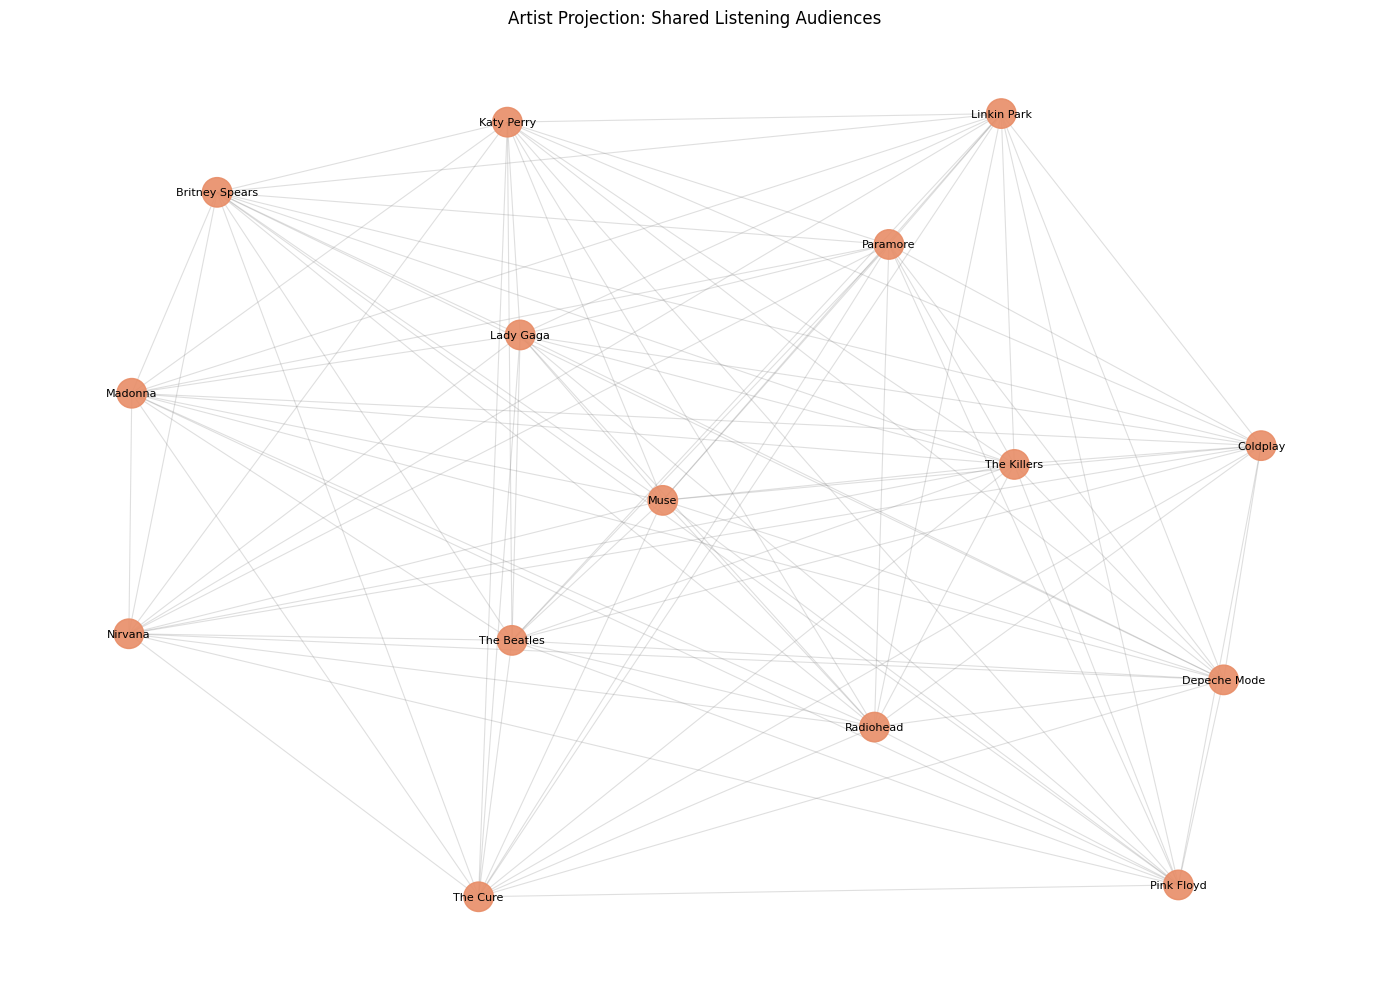

Minimum shared listeners: 50
Nodes remaining: 194
Edges remaining: 1623


In [10]:
# # Identify artist nodes in the original bipartite network
artist_nodes = [
    node
    for node, data in B.nodes(data=True)
    if data["node_type"] == "artist"
]

# Project the bipartite network onto the artist group
artist_projection = nx.bipartite.weighted_projected_graph(
    B,
    artist_nodes
)

print("Original bipartite network")
print("Total nodes:", B.number_of_nodes())
print("Total edges:", B.number_of_edges())

print("\nArtist projection")
print("Artist nodes:", artist_projection.number_of_nodes())
print("Artist-to-artist edges:", artist_projection.number_of_edges())


# Calculate artist degree in the projected network
artist_degree = pd.DataFrame([
    {
        "artistID": int(node.split("_")[1]),
        "artist": B.nodes[node]["artist_name"],
        "connected_artists": degree
    }
    for node, degree in artist_projection.degree()
])

# Display the 15 artists connected to the most other artists
top_projected_artists = artist_degree.sort_values(
    "connected_artists",
    ascending=False
).head(15)

display(top_projected_artists)

# Calculate weighted degree in the artist projection
artist_projection_strength = pd.DataFrame([
    {
        "artistID": int(node.split("_")[1]),
        "artist": B.nodes[node]["artist_name"],
        "shared_listener_strength": sum(
            data["weight"]
            for _, _, data in artist_projection.edges(
                node, data=True
            )
        )
    }
    for node in artist_projection.nodes()
])

# Rank artists by total shared-listener strength
top_shared_audiences = artist_projection_strength.sort_values(
    "shared_listener_strength",
    ascending=False
).head(15)

display(top_shared_audiences)

# Select the 30 artists with the highest projected degree
top_artist_ids = set(
    top_projected_artists["artistID"].head(30)
)

top_artist_nodes = {
    f"artist_{artist_id}"
    for artist_id in top_artist_ids
    if f"artist_{artist_id}" in artist_projection
}

# Extract the subgraph containing these artists
projection_subgraph = artist_projection.subgraph(
    top_artist_nodes
).copy()

# Calculate positions
pos = nx.spring_layout(
    projection_subgraph,
    seed=42,
    weight="weight"
)

# Scale node sizes by projected degree
degrees = dict(projection_subgraph.degree())

node_sizes = [
    100 + degrees[node] * 25
    for node in projection_subgraph.nodes()
]

# Draw the network
plt.figure(figsize=(14, 10))

nx.draw_networkx_edges(
    projection_subgraph,
    pos,
    alpha=0.25,
    edge_color="gray",
    width=0.8
)

nx.draw_networkx_nodes(
    projection_subgraph,
    pos,
    node_size=node_sizes,
    node_color="#E88D67",
    alpha=0.9
)

labels = {
    node: projection_subgraph.nodes[node]["artist_name"]
    for node in projection_subgraph.nodes()
}

nx.draw_networkx_labels(
    projection_subgraph,
    pos,
    labels=labels,
    font_size=8
)

plt.title("Artist Projection: Shared Listening Audiences")
plt.axis("off")
plt.tight_layout()
plt.show()


# Retain artist pairs with 50 shared listeners
min_shared_listeners = 50

strong_artist_edges = [
    (u, v, data)
    for u, v, data in artist_projection.edges(data=True)
    if data["weight"] >= min_shared_listeners
]

# Construct the filtered artist projection
artist_projection_filtered = nx.Graph()

artist_projection_filtered.add_nodes_from(
    artist_projection.nodes(data=True)
)

artist_projection_filtered.add_edges_from(
    strong_artist_edges
)

# Remove isolates to focus on connected relationships
artist_projection_filtered.remove_nodes_from(
    list(nx.isolates(artist_projection_filtered))
)

print("Minimum shared listeners:", min_shared_listeners)
print("Nodes remaining:", artist_projection_filtered.number_of_nodes())
print("Edges remaining:", artist_projection_filtered.number_of_edges())

#### Projecting the Two-Mode Network onto Users

I projected the original bipartite network onto users to examine shared listening interests. In this network, two users are connected when they have listened to at least one common artist, and the edge weight represents the number of artists they share. The projection contains 1,892 users and 1,014,138 user-to-user edges.

User 1368 has the highest degree, with connections to 1,714 other users, followed by user 458 with 1,705 and user 1469 with 1,693. This suggests that these users share at least one artist with a large proportion of the user group.

When ranking users by shared-artist strength, user 1071 ranks first with a score of 11,362, followed by user 1272 with 11,052 and user 1132 with 10,958. While degree measures the number of users with whom someone shares artists, weighted strength sums the number of shared artists across those connections.

The user projection is very dense, indicating substantial overlap in listening histories across the dataset. However, sharing artists does not necessarily mean users have identical musical preferences. The results also do not establish how similar their overall listening habits are, since users may listen to the same artists at very different frequencies.

The projection provides another perspective on the user group by showing how widely listening interests overlap between individuals. Together with the artist projection, it demonstrates how the same two-mode network can reveal different patterns depending on which group is projected.

User projection
User nodes: 1892
User-to-user edges: 1014138


,user,connected_users
1238,user_1368,1714
427,user_458,1705
1327,user_1469,1693
803,user_864,1677
1019,user_1114,1668
1035,user_1133,1668
98,user_103,1662
1359,user_1503,1662
294,user_315,1656
637,user_685,1652


,user,shared_artist_strength
980,user_1071,11362
1155,user_1272,11052
1034,user_1132,10958
1643,user_1820,10796
1261,user_1394,10668
1450,user_1606,10603
317,user_339,10581
586,user_632,10414
1644,user_1821,10385
1619,user_1795,10377


Users remaining: 1608
Edges remaining: 93506


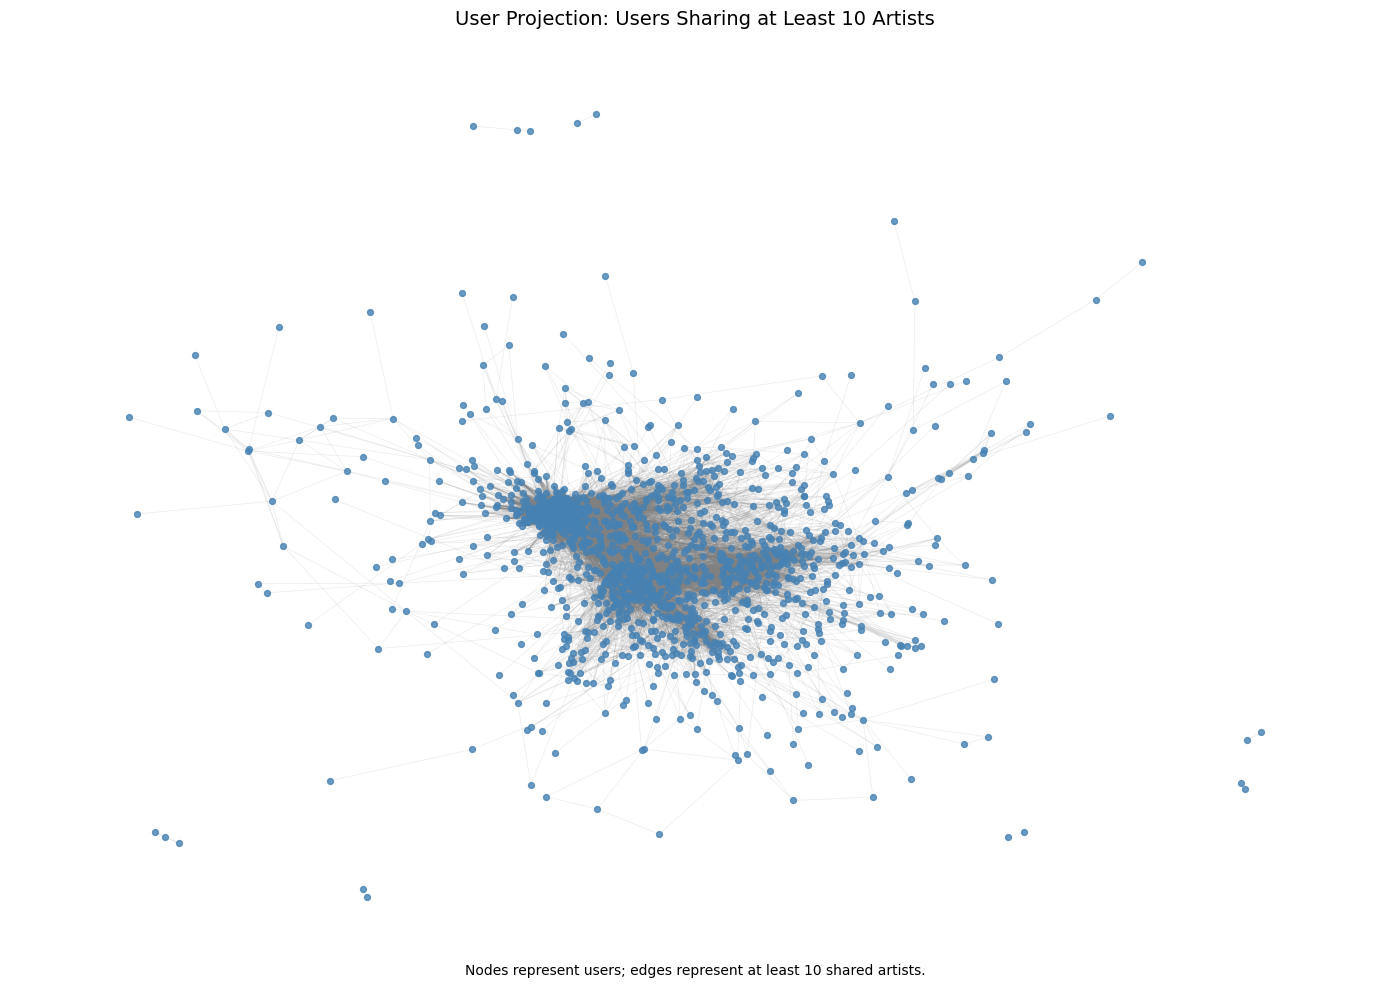

In [12]:
# Identify user nodes
user_nodes = [
    node
    for node, data in B.nodes(data=True)
    if data["node_type"] == "user"]

# Project the bipartite network onto users
user_projection = nx.bipartite.weighted_projected_graph(
    B,
    user_nodes)

print("User projection")
print("User nodes:", user_projection.number_of_nodes())
print("User-to-user edges:", user_projection.number_of_edges())

user_degree = pd.DataFrame([
    {
        "user": node,
        "connected_users": degree
    }
    for node, degree in user_projection.degree()])

display(
    user_degree.sort_values(
        "connected_users",
        ascending=False
    ).head(15)
)

user_strength = pd.DataFrame([
    {
        "user": node,
        "shared_artist_strength": sum(
            data["weight"]
            for _, _, data in user_projection.edges(
                node, data=True
            )
        )
    }
    for node in user_projection.nodes()
])

display(
    user_strength.sort_values(
        "shared_artist_strength",
        ascending=False
    ).head(15))

# Filter user projection by shared artists
min_shared_artists = 10

user_projection_filtered = nx.Graph(
    (u, v, data)
    for u, v, data in user_projection.edges(data=True)
    if data["weight"] >= min_shared_artists
)

print("Users remaining:", user_projection_filtered.number_of_nodes())
print("Edges remaining:", user_projection_filtered.number_of_edges())

# Remove isolated users for a cleaner visualization
user_projection_filtered.remove_nodes_from(
    list(nx.isolates(user_projection_filtered))
)

# Calculate node positions
pos = nx.spring_layout(
    user_projection_filtered,
    seed=42,
    weight="weight",
    k=0.25
)

# Draw network
plt.figure(figsize=(14, 10))

nx.draw_networkx_edges(
    user_projection_filtered,
    pos,
    alpha=0.15,
    edge_color="gray",
    width=0.5
)

nx.draw_networkx_nodes(
    user_projection_filtered,
    pos,
    node_size=18,
    node_color="#4682B4",
    alpha=0.8
)

plt.title(
    "User Projection: Users Sharing at Least 10 Artists",
    fontsize=14
)
plt.figtext(
    0.5, 0.02,
    "Nodes represent users; edges represent at least 10 shared artists.",
    ha="center",
    fontsize=10
)

plt.axis("off")
plt.tight_layout()
plt.show()

#### Reducing the Network Using the Island Method

I reduced the original two-mode user–artist network using the island method, which filters connections according to their listening weights. The original network contains 19,524 nodes and 92,834 edges, making it difficult to examine individual relationships and identify meaningful patterns. By removing relationships below selected weight thresholds, I can focus on stronger recorded listening activity and investigate how the network's structure changes.

I tested five minimum listening-weight thresholds based on the 50th, 75th, 90th, 95th, and 99th percentiles of the weight distribution. At each threshold, I retained only edges whose weights met or exceeded the cutoff and examined the remaining nodes, edges, connected components, and largest connected component, also called the largest island.

The results show that increasing the threshold substantially reduces the network. At 260 listens, the network contains 46,420 edges and 11,316 nodes, while at 7,228 listens, only 929 edges and 850 nodes remain. The visualizations illustrate this change: the number of edges and the size of the largest island decrease as the threshold increases, while the number of connected components rises from 21 to 79. This happens because removing edges can disconnect previously connected users and artists, creating smaller islands or isolated nodes.

I selected a threshold of 1,387 listens, corresponding to the 90th percentile, for further analysis. At this threshold, the network contains 4,116 nodes and 9,288 edges, compared with 19,524 nodes and 92,834 edges in the original network. The reduced network includes 1,293 users and 2,823 artists, divided into 60 connected components. The largest island contains 3,989 nodes and 9,220 edges, meaning that approximately 96.9% of the remaining nodes and 99.3% of the remaining edges belong to this component.

I also examined the artists with the most user connections in the largest island. Britney Spears ranks first with 217 connections, followed by Lady Gaga with 181. Rihanna and Christina Aguilera each have 129 connections, while Madonna has 117. The Beatles have 105 connections, followed by Depeche Mode with 95 and Paramore with 92. These results identify artists who remain connected to many users through relationships meeting the selected listening threshold.

The reduction also provides an initial insight into the two groups. Of the original 1,892 users, 1,293 remain in the reduced network, while the number of artists decreases from 17,632 to 2,823. This shows that the filtering process retains a subset of users and artists connected through stronger recorded listening relationships. However, excluded users are not necessarily less engaged, and excluded artists are not necessarily less popular overall; their relationships simply do not meet the selected threshold.

Overall, the island method substantially reduces the network while preserving one dominant connected component. The threshold of 1,387 provides a manageable network for examining differences between users and artists. However, this threshold is an analytical choice rather than a definitive boundary between important and unimportant relationships. The results describe recorded listening activity and connectivity within the filtered network, not users' complete musical preferences or artists' total popularity.

,threshold,nodes,edges,users,artists,components,largest_island_nodes
0,260,11316,46420,1735,9581,21,11236
1,614,7155,23221,1574,5581,35,7054
2,1387,4116,9288,1293,2823,60,3989
3,2328,2698,4643,1020,1678,67,2543
4,7228,850,929,456,394,79,653


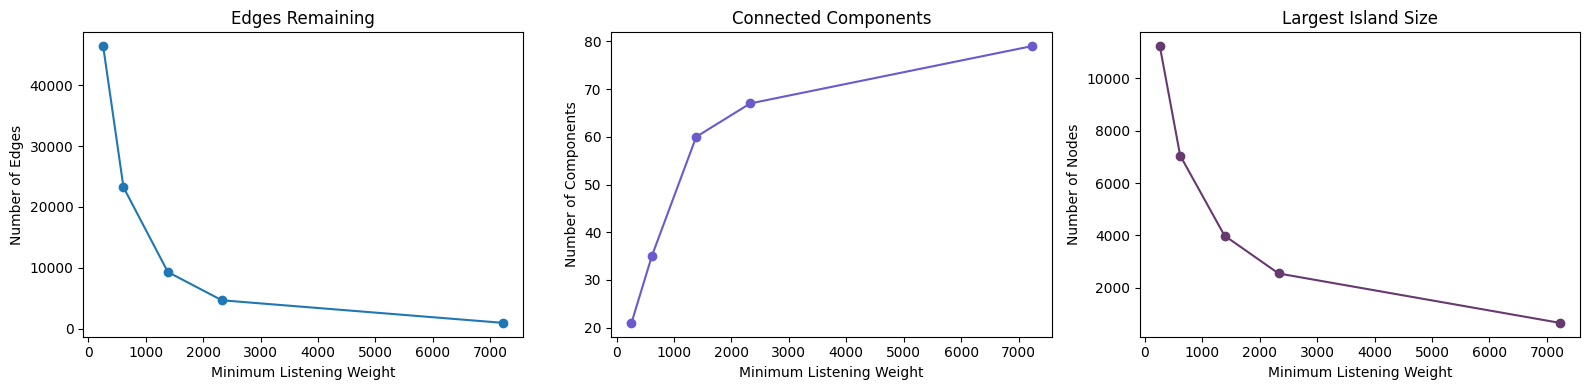

Chosen threshold: 1387
Nodes remaining: 4116
Edges remaining: 9288
Connected components: 60
Largest island nodes: 3989
Largest island edges: 9220


,artistID,artist,listeners_in_island
46,289,Britney Spears,217
38,89,Lady Gaga,181
45,288,Rihanna,129
49,292,Christina Aguilera,129
16,67,Madonna,117
176,227,The Beatles,105
21,72,Depeche Mode,95
97,498,Paramore,92
57,300,Katy Perry,91
148,190,Muse,72


In [ ]:
# Compare possible thresholds

# Generate candidate thresholds from the weight distribution
quantiles = [0.50, 0.75, 0.90, 0.95, 0.99]

thresholds = sorted(set(
    int(edges_named["weight"].quantile(q))
    for q in quantiles
))

results = []

for threshold in thresholds:
    filtered = edges_named[
        edges_named["weight"] >= threshold
    ]

    # Build the filtered two-mode network
    B_test = nx.Graph()

    for row in filtered.itertuples(index=False):
        user_node = f"user::{row.userID}"
        artist_node = f"artist::{row.artistID}"

        B_test.add_node(user_node, node_type="user")
        B_test.add_node(
            artist_node,
            node_type="artist",
            artist_name=row.artist_name
        )

        B_test.add_edge(
            user_node,
            artist_node,
            weight=row.weight
        )

    # Identify connected components
    components = sorted(
        nx.connected_components(B_test),
        key=len,
        reverse=True
    )

    results.append({
        "threshold": threshold,
        "nodes": B_test.number_of_nodes(),
        "edges": B_test.number_of_edges(),
        "users": sum(
            d["node_type"] == "user"
            for _, d in B_test.nodes(data=True)
        ),
        "artists": sum(
            d["node_type"] == "artist"
            for _, d in B_test.nodes(data=True)
        ),
        "components": len(components),
        "largest_island_nodes": (
            len(components[0]) if components else 0
        )
    })

threshold_results = pd.DataFrame(results)

display(threshold_results)


# Plot the effect of each threshold

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(
    threshold_results["threshold"],
    threshold_results["edges"],
    marker="o"
)
axes[0].set_title("Edges Remaining")
axes[0].set_xlabel("Minimum Listening Weight")
axes[0].set_ylabel("Number of Edges")

axes[1].plot(
    threshold_results["threshold"],
    threshold_results["components"],
    marker="o",
    color="#6A5ACD"
)
axes[1].set_title("Connected Components")
axes[1].set_xlabel("Minimum Listening Weight")
axes[1].set_ylabel("Number of Components")

axes[2].plot(
    threshold_results["threshold"],
    threshold_results["largest_island_nodes"],
    marker="o",
    color="#673A6F"
)
axes[2].set_title("Largest Island Size")
axes[2].set_xlabel("Minimum Listening Weight")
axes[2].set_ylabel("Number of Nodes")

plt.tight_layout()
plt.show()

# Choose a threshold and examine the largest island

# Temporary starting point: 90th-percentile threshold
chosen_threshold = int(edges_named["weight"].quantile(0.90))

filtered = edges_named[
    edges_named["weight"] >= chosen_threshold
]

B_reduced = nx.Graph()

for row in filtered.itertuples(index=False):
    user_node = f"user::{row.userID}"
    artist_node = f"artist::{row.artistID}"

    B_reduced.add_node(user_node, node_type="user")
    B_reduced.add_node(
        artist_node,
        node_type="artist",
        artist_name=row.artist_name
    )

    B_reduced.add_edge(
        user_node,
        artist_node,
        weight=row.weight
    )

components = sorted(
    nx.connected_components(B_reduced),
    key=len,
    reverse=True
)

print("Chosen threshold:", chosen_threshold)
print("Nodes remaining:", B_reduced.number_of_nodes())
print("Edges remaining:", B_reduced.number_of_edges())
print("Connected components:", len(components))

if components:
    largest_island = B_reduced.subgraph(components[0]).copy()

    print("Largest island nodes:", largest_island.number_of_nodes())
    print("Largest island edges:", largest_island.number_of_edges())

    island_artists = pd.DataFrame([
        {
            "artistID": int(node.split("::")[1]),
            "artist": data["artist_name"],
            "listeners_in_island": largest_island.degree(node)
        }
        for node, data in largest_island.nodes(data=True)
        if data["node_type"] == "artist"
    ]).sort_values(
        "listeners_in_island",
        ascending=False
    )

    display(island_artists.head(15))

### Comparing the Original and Reduced Networks

I compared the original network with the reduced network to evaluate the effect of applying the selected threshold of 1,387 listens. The original network contains 19,524 nodes, including 1,892 users and 17,632 artists, connected by 92,834 edges. After filtering, the reduced network contains 4,116 nodes, consisting of 1,293 users and 2,823 artists, connected by 9,288 edges.

This represents a reduction of approximately 78.9% of the nodes and 90.0% of the edges. The substantial decrease in edges shows that many recorded listening relationships fall below the selected threshold, making the network considerably smaller and easier to analyze.

The reduction affects both groups: 599 fewer users and 14,809 fewer artists remain in the network. This indicates that fewer users and artists have relationships meeting the threshold, with a particularly large reduction in the number of artists. However, this does not necessarily mean that the excluded users are less engaged or the excluded artists are less popular overall; it means that they have no retained relationships meeting the selected cutoff.

The comparison confirms that the island method produces a more manageable network while preserving stronger recorded listening relationships. This reduced network provides the basis for examining connected components and investigating which users and artists remain most prominent.

In [ ]:
# original

original_users = edges_named["userID"].nunique()
original_artists = edges_named["artistID"].nunique()
original_nodes = original_users + original_artists

# Reduced network (using your chosen threshold)
chosen_threshold = thresholds[2]  # 90th percentile

filtered = edges_named[
    edges_named["weight"] >= chosen_threshold
]

new_users = filtered["userID"].nunique()
new_artists = filtered["artistID"].nunique()
new_nodes = new_users + new_artists

# Display comparison
comparison = pd.DataFrame({
    "Network": ["Original", "Reduced"],
    "User nodes": [original_users, new_users],
    "Artist nodes": [original_artists, new_artists],
    "Total nodes": [original_nodes, new_nodes],
    "Edges": [len(edges_named), len(filtered)]
})

display(comparison)

print(f"Nodes removed: {original_nodes - new_nodes:,}")
print(
    f"Percentage of nodes removed: "
    f"{100 * (original_nodes - new_nodes) / original_nodes:.2f}%"
)

,Network,User nodes,Artist nodes,Total nodes,Edges
0,Original,1892,17632,19524,92834
1,Reduced,1293,2823,4116,9288


Nodes removed: 15,408
Percentage of nodes removed: 78.92%


#### Analyzing Connected Components and the Largest Island

I analyzed the connected components of the reduced network to understand how users and artists remain connected after applying the minimum listening-weight threshold of 1,387. A connected component, or island, is a group of nodes in which every node can be reached from every other node through a path of connections. This analysis helps determine whether stronger listening relationships form one large interconnected network or several smaller, disconnected groups.

The reduced network contains 60 connected components. The largest component contains 3,989 nodes and 9,220 edges, while the second- and third-largest components contain only four nodes each. The largest island therefore accounts for approximately 96.9% of all remaining nodes and 99.3% of all remaining edges. This shows that nearly all retained listening relationships belong to one dominant, interconnected structure, while the remaining nodes form small disconnected groups.

I then examined the artists with the highest numbers of user connections within the largest island. Britney Spears ranks first with 217 connections, followed by Lady Gaga with 181. Rihanna and Christina Aguilera each have 129 connections, while Madonna has 117. The Beatles, Depeche Mode, Paramore, and Katy Perry follow with 105, 95, 92, and 91 connections, respectively.

These findings provide insight into the artist group by identifying which artists remain connected to the greatest number of users through stronger listening relationships. Britney Spears and Lady Gaga have particularly high connectivity, while the presence of artists such as The Beatles and Depeche Mode shows that the largest island includes a range of artists rather than being limited to a single musical style. However, these connection counts measure the number of users linked to each artist in the filtered network, not their total audience or listening activity across the original dataset.

The component analysis also provides insight into the relationship between the two groups. Despite removing approximately 90% of the original edges, the remaining relationships form one dominant connected component. This suggests that many of the stronger user–artist relationships remain interconnected through shared users and artists. Nevertheless, the results describe the structure of the filtered network and do not establish that users share the same musical preferences or that the most connected artists are necessarily the most popular overall.

In [ ]:
# Build the reduced network
B_reduced = nx.Graph()

for row in filtered.itertuples(index=False):
    user_node = f"user::{row.userID}"
    artist_node = f"artist::{row.artistID}"

    B_reduced.add_node(user_node, node_type="user")
    B_reduced.add_node(
        artist_node,
        node_type="artist",
        artist_name=row.artist_name
    )

    B_reduced.add_edge(
        user_node,
        artist_node,
        weight=row.weight
    )

# Identify connected components (islands)
components = sorted(
    nx.connected_components(B_reduced),
    key=len,
    reverse=True
)

print("Number of islands:", len(components))
print("Largest island sizes:", [len(c) for c in components[:10]])

# Extract the largest island
largest_island = B_reduced.subgraph(components[0]).copy()

print("Largest island nodes:", largest_island.number_of_nodes())
print("Largest island edges:", largest_island.number_of_edges())

# Find artists with the most user connections in the largest island
island_artists = pd.DataFrame([
    {
        "artist": data["artist_name"],
        "user_connections": largest_island.degree(node)
    }
    for node, data in largest_island.nodes(data=True)
    if data["node_type"] == "artist"
]).sort_values(
    "user_connections",
    ascending=False
)

display(island_artists.head(15))

Number of islands: 60
Largest island sizes: [3989, 4, 4, 3, 3, 3, 3, 3, 2, 2]
Largest island nodes: 3989
Largest island edges: 9220


,artist,user_connections
46,Britney Spears,217
38,Lady Gaga,181
45,Rihanna,129
49,Christina Aguilera,129
16,Madonna,117
176,The Beatles,105
21,Depeche Mode,95
97,Paramore,92
57,Katy Perry,91
148,Muse,72


#### Analyzing User Connections in the Largest Island

I examined the users with the highest numbers of artist connections in the largest island of the reduced network. Each connection represents a user–artist relationship with a listening weight of at least 1,387. This analysis helps identify users who maintain strong listening relationships with a wide range of artists.

The results show that the highest observed degree is 50 artist connections, shared by 12 users, followed by users with 49 and 48 connections. This indicates that some users maintain strong recorded listening relationships with many different artists, while others have fewer connections in the reduced network.

These findings provide insight into the user group by revealing differences in the breadth of listening relationships. However, the number of connections measures how many distinct artists are linked to a user, not the user's total listening volume. Furthermore, because the analysis includes only relationships meeting the selected threshold and belonging to the largest island, these results do not represent users' complete listening histories.

The results also help explain how users connect the two groups within the network. A user connected to multiple artists can provide a path between those artists, even though there are no direct connections between artists themselves. This helps explain why many users and artists remain part of one dominant connected component after filtering. Overall, the user analysis suggests that some individuals have a broader range of strong listening relationships than others, complementing the artist analysis, which identifies the artists connected to the greatest number of users.

In [ ]:
# Identify users with the most artist connections
island_users = pd.DataFrame([
    {
        "userID": int(node.split("::")[1]),
        "artist_connections": largest_island.degree(node)
    }
    for node, data in largest_island.nodes(data=True)
    if data["node_type"] == "user"
]).sort_values(
    "artist_connections",
    ascending=False
)

display(island_users.head(15))

,userID,artist_connections
71,104,50
255,387,50
468,734,50
1159,1971,50
721,1195,50
1180,2007,50
1175,2000,50
518,831,50
890,1504,50
296,455,50


#### Analyzing Listening Strength Among Users and Artists

I examined listening strength within the largest island of the reduced network to compare the breadth and intensity of listening relationships among users and artists. Listening strength is calculated by summing the weights of a node's connections. Unlike degree, which measures the number of connections, listening strength measures the total recorded listening activity associated with those connections. Comparing these measures helps reveal whether a node's activity comes from many relationships or from a smaller number of particularly strong ones.

Among artists, Britney Spears has the highest listening strength, totaling 2,242,053 across 217 user connections. Depeche Mode ranks second, with 1,229,904 across 95 connections, followed by Lady Gaga, with 1,101,655 across 181 connections. These results show that the artists differ not only in the number of users connected to them but also in the cumulative listening activity represented by those relationships.

The comparison between Shakira and Rihanna illustrates this distinction. Shakira has 51 user connections and a listening strength of 579,878, while Rihanna has 129 connections and a listening strength of 747,370. Although Rihanna is connected to more than twice as many users, her listening strength is not proportionally higher. This suggests that the weights of individual relationships also play an important role in determining an artist's total listening strength.

A similar pattern appears among users. User 757 has a listening strength of 469,614 across 17 artist connections, while user 2000 has a similar listening strength of 468,409 across 50 connections. This suggests that user 757's recorded listening activity is concentrated across fewer retained relationships, whereas user 2000's activity is spread across a broader range of artists. User 2071 provides another example, with a listening strength of 327,104 across only two artist connections.

These findings reveal differences within both groups. Among artists, some combine connections to many users with high cumulative listening strength, while others accumulate substantial listening activity through fewer connections. Among users, some maintain strong relationships with a wide range of artists, while others concentrate much of their recorded listening activity on a smaller number of artists.

Overall, degree and listening strength provide complementary insights into the two-mode network. Degree measures the breadth of a node's connections, while listening strength measures the combined weight of those connections. Neither measure alone fully describes a user's listening behavior or an artist's audience. Importantly, all results are restricted to the largest island, where only relationships with at least 1,387 recorded listens were retained. Therefore, these values describe the strongest relationships represented in the filtered network rather than complete listening histories, personal preferences, or overall musical engagement.

In [ ]:
# Calculate total listening strength for each node
strength = dict(largest_island.degree(weight="weight"))

# Combine results
strength_df = pd.DataFrame([
    {
        "node_id": node,
        "node_type": data["node_type"],
        "artist_name": data.get("artist_name"),
        "number_of_connections": largest_island.degree(node),
        "listening_strength": strength[node]
    }
    for node, data in largest_island.nodes(data=True)
])

# Top 10 artists by total listening strength
print("Top 10 artists by listening strength:")

display(
    strength_df[strength_df["node_type"] == "artist"]
    .sort_values("listening_strength", ascending=False)
    [["artist_name", "number_of_connections", "listening_strength"]]
    .head(10)
)

# Top 10 users by total listening strength
print("Top 10 users by listening strength:")

display(
    strength_df[strength_df["node_type"] == "user"]
    .sort_values("listening_strength", ascending=False)
    [["node_id", "number_of_connections", "listening_strength"]]
    .head(10)
)

Top 10 artists by listening strength:


,artist_name,number_of_connections,listening_strength
49,Britney Spears,217,2242053
22,Depeche Mode,95,1229904
39,Lady Gaga,181,1101655
52,Christina Aguilera,129,918646
105,Paramore,92,843576
17,Madonna,117,802738
48,Rihanna,129,747370
277,Shakira,51,579878
206,The Beatles,105,500318
88,Taylor Swift,65,454328


Top 10 users by listening strength:


,node_id,number_of_connections,listening_strength
2035,user::757,17,469614
3799,user::2000,50,468409
2986,user::1418,27,399636
3315,user::1642,6,378019
2568,user::1094,12,361428
3669,user::1942,50,348527
3891,user::2031,50,329980
3942,user::2071,2,327104
1203,user::387,50,322661
1520,user::514,10,308307


#### Interpreting the Network Visualization

The network graph illustrates the relationships between users and the 15 most connected artists within the largest island of the reduced network. Blue nodes represent users, orange nodes represent artists, and edges represent listening relationships with weights of at least 1,387 listens. The visualization provides a graphical overview of how users connect to prominent artists through stronger recorded listening relationships.

Britney Spears and Lady Gaga appear among the most connected artists, alongside Rihanna, Christina Aguilera, and Madonna, consistent with the earlier degree analysis. The presence of artists such as The Beatles, Depeche Mode, Paramore, Muse, and Radiohead also shows that the network contains relationships involving a variety of artists. This reinforces the finding that artists differ in the number of users connected to them within the filtered network.

The graph also illustrates the role of users in connecting artists. Users linked to multiple artists create paths between those artists within the network, helping explain how different artist audiences can belong to the same connected component. Some artists appear near a dense central cluster, while others appear farther away. However, these positions are determined by the layout algorithm and do not necessarily indicate separate communities or differences in musical preferences.

The visualization complements the degree and listening-strength analyses by showing how the two groups are interconnected. It illustrates differences in artist connectivity and how users connect across multiple artists. However, because the graph displays only the 15 most connected artists and their associated users, it represents a focused view rather than the entire largest island. Its findings should therefore be interpreted within the context of the filtered network rather than as a complete picture of users' listening histories or artists' overall popularity.

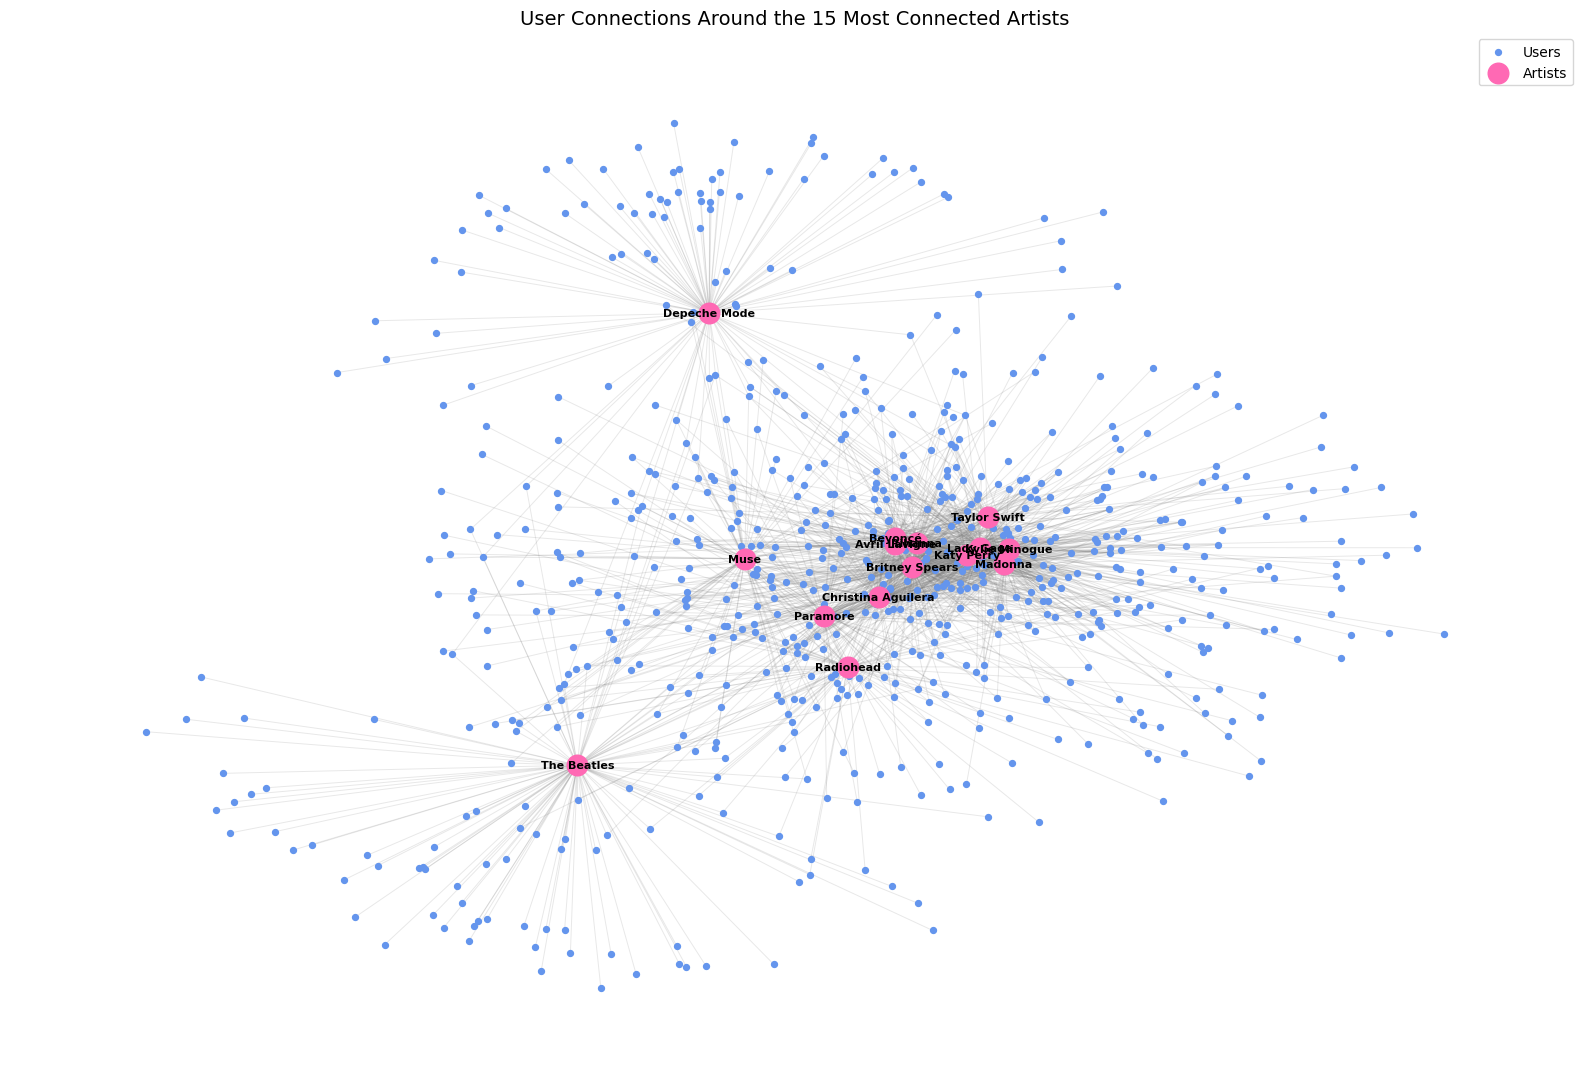

Artists displayed: 15
Users displayed: 700
Total nodes displayed: 715
Total edges displayed: 1569


In [ ]:
# Identify the 15 most connected artists in the largest island
top_artist_nodes = [
    node
    for node, data in largest_island.nodes(data=True)
    if data["node_type"] == "artist"
]

top_artist_nodes = sorted(
    top_artist_nodes,
    key=lambda node: largest_island.degree(node),
    reverse=True
)[:15]

# Include users connected to at least one of these artists
focused_nodes = set(top_artist_nodes)

for artist in top_artist_nodes:
    focused_nodes.update(largest_island.neighbors(artist))

# Create the focused subnetwork
focused_graph = largest_island.subgraph(focused_nodes).copy()

# Calculate node positions
pos = nx.spring_layout(focused_graph, seed=42, k=0.6)

# Separate users and artists
user_nodes = [
    node for node, data in focused_graph.nodes(data=True)
    if data["node_type"] == "user"
]

artist_nodes = [
    node for node, data in focused_graph.nodes(data=True)
    if data["node_type"] == "artist"
]

# Draw network
plt.figure(figsize=(16, 11))

nx.draw_networkx_edges(
    focused_graph,
    pos,
    alpha=0.18,
    edge_color="gray",
    width=0.7
)

nx.draw_networkx_nodes(
    focused_graph,
    pos,
    nodelist=user_nodes,
    node_color="cornflowerblue",
    node_size=18,
    label="Users"
)

nx.draw_networkx_nodes(
    focused_graph,
    pos,
    nodelist=artist_nodes,
    node_color="#FF69B4",
    node_size=220,
    label="Artists"
)

# Label only the selected artists
artist_labels = {
    node: focused_graph.nodes[node]["artist_name"]
    for node in artist_nodes
}

nx.draw_networkx_labels(
    focused_graph,
    pos,
    labels=artist_labels,
    font_size=8,
    font_weight="bold"
)

plt.title(
    "User Connections Around the 15 Most Connected Artists",
    fontsize=14
)
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

print("Artists displayed:", len(artist_nodes))
print("Users displayed:", len(user_nodes))
print("Total nodes displayed:", focused_graph.number_of_nodes())
print("Total edges displayed:", focused_graph.number_of_edges())

#### Conclusion

This project used the HetRec 2011 Last.fm dataset to investigate relationships between users and artists through two-mode network analysis, network projection, and the island method. The goal was to reduce a large network and determine what can be inferred about each group and their relationships.

The original network contained 19,524 nodes, consisting of 1,892 users and 17,632 artists, connected through 92,834 user–artist relationships. Applying a minimum listening-weight threshold of 1,387 reduced the network to 4,116 nodes and 9,288 edges, removing approximately 78.9% of the nodes and 90.0% of the edges. Despite this reduction, the largest connected component retained 3,989 nodes and 9,220 edges, accounting for approximately 96.9% of the remaining nodes and 99.3% of the remaining edges.

What can be inferred about the user group?

The results show that users differ in the breadth and intensity of their listening relationships. Some users maintain strong connections with many artists, while others concentrate their listening activity across fewer connections. For example, user 757 had a listening strength of 469,614 across 17 artist connections, while user 2000 had a similar strength of 468,409 across 50 connections. This demonstrates that the number of artists a user listens to does not necessarily correspond to their total listening activity.

The user projection provided another perspective by examining shared listening interests between users. It contained 1,892 users and 1,014,138 edges, indicating substantial overlap in listening histories. User 1368 had the highest degree, with connections to 1,714 other users, while user 1071 had the highest shared-artist strength, at 11,362. These measures show that users differ in how widely their listening interests overlap with others. However, sharing artists does not necessarily mean users have identical musical preferences.

What can be inferred about the artist group?

The results show that artists differ in audience reach and cumulative listening activity. In the largest island of the reduced bipartite network, Britney Spears had the most user connections, with 217, and the highest listening strength, at 2,242,053. Depeche Mode also had high listening strength despite having fewer user connections than Lady Gaga. This demonstrates that the number of connected users and the total listening activity associated with an artist are different measures.

The artist projection examined audience overlap between artists. The Beatles had the highest degree, with connections to 5,925 other artists, while Lady Gaga had the highest shared-listener strength, at 29,668. This shows that an artist connected to many other artists does not necessarily have the highest cumulative shared-listener strength. To make the projection easier to analyze, I retained only artist pairs with at least 50 shared listeners. The resulting network contained 194 artists and 1,623 edges, focusing the analysis on stronger audience overlaps.

What can be inferred about the relationship between the groups?

The connected-component analysis showed that most retained user–artist relationships belonged to one dominant island. This suggests that stronger listening relationships form a highly interconnected structure rather than many similarly sized disconnected groups. Users connected to multiple artists help link different parts of the network.

The two projections provide additional insight into these relationships. The artist projection shows which artists share audiences, while the user projection shows which users share listening interests. Together, they demonstrate how the same bipartite network can reveal different patterns depending on which group is being examined.

Limitations and final observations

There are several limitations to these findings. The island method retains only user–artist relationships with at least 1,387 listens, so its results do not represent users' complete listening histories. Similarly, the projections use selected thresholds to reduce network density, and excluded connections may still be meaningful. Shared listeners do not necessarily indicate musical similarity, and shared-artist strength counts overlap across pairs rather than unique individuals.

Overall, this project demonstrates how two-mode network analysis, projection, and the island method can simplify a large dataset and reveal differences between users and artists. The results show that users vary in their listening activity and overlap with other listeners, while artists vary in their audience reach and overlap with other artists. Using degree, listening strength, and shared-listener measures together provides a broader understanding of the network than any single measure alone.